# 02 · Cleaning, and the hot places that are not fires

> **What and why**
>
> - Satellites also see factories, gas flares, volcanoes and ships. We must remove them, or they look like fires.
> - NASA labels these places in its science quality data, but not in its near real time data (the newest months).
> - We build a mask from the labelled years and test it on years it never saw.
> - We also show the confidence rule and the few strange values we found.

In [1]:
import sys, os
from pathlib import Path
REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(REPO)); sys.path.insert(0, str(REPO / 'style'))
import pandas as pd, numpy as np, duckdb, matplotlib.pyplot as plt
import fireharmony_style as fh
from fireharmony import config as C, features as FE
fh.use(); pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
FIG = REPO / 'report' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
con = C.connect()
from fireharmony import static_mask as SM
RAW = [str(C.raw('firms', f'year={y}', 'detections.parquet')) for y in C.years()]
FAMILY = "CASE WHEN sensor = 'MODIS' THEN 'MODIS' ELSE 'VIIRS' END"

## 1. What NASA's labels say

In science quality data each hotspot has a type: 0 vegetation fire, 1 active volcano, 2 other hot land source (such as industry), 3 offshore. Near real time rows have no type.

In [2]:
types = con.execute(f'''
  WITH c AS (SELECT {FAMILY} AS family, quality, coalesce(CAST(type AS VARCHAR), 'no label') AS type, count(*) n FROM read_parquet({RAW}) GROUP BY 1, 2, 3)
  SELECT *, round(100.0 * n / sum(n) OVER (PARTITION BY family, quality), 2) AS pct FROM c ORDER BY 1, 2, 3''').df()
types

,family,quality,type,n,pct
0,MODIS,nrt,no label,1670724,100.00
1,MODIS,sp,0,108082907,95.28
2,MODIS,sp,1,196202,0.17
3,MODIS,sp,2,4501680,3.97
4,MODIS,sp,3,657369,0.58
5,VIIRS,nrt,no label,75069501,100.00
6,VIIRS,sp,0,417803687,92.76
7,VIIRS,sp,1,509248,0.11
8,VIIRS,sp,2,28802660,6.39
9,VIIRS,sp,3,3307612,0.73


## 2. Confidence

Each hotspot also has a confidence. Our main record drops the low class (MODIS below 30%, VIIRS 'low'). A sensitivity test keeps them.

In [3]:
conf = con.execute(f'''
  WITH d AS (SELECT {FAMILY} AS family,
                    CASE WHEN sensor = 'MODIS' THEN CASE WHEN confidence_pct < 30 THEN 'low' WHEN confidence_pct < 80 THEN 'nominal' ELSE 'high' END
                         ELSE CASE confidence WHEN 'l' THEN 'low' WHEN 'n' THEN 'nominal' ELSE 'high' END END AS conf_class
             FROM read_parquet({RAW}) WHERE type = 0),
       c AS (SELECT family, conf_class, count(*) n FROM d GROUP BY 1, 2)
  SELECT *, round(100.0 * n / sum(n) OVER (PARTITION BY family), 1) AS pct FROM c ORDER BY 1, 2''').df()
conf

,family,conf_class,n,pct
0,MODIS,high,31303654,29.0
1,MODIS,low,4993082,4.6
2,MODIS,nominal,71786171,66.4
3,VIIRS,high,24231490,5.8
4,VIIRS,low,49984119,12.0
5,VIIRS,nominal,343588078,82.2


## 3. A mask for rows without labels

We use small hexagons (level 8, about 0.74 km2). We mask a hexagon for one of three reasons. Science quality data saw at least 3 static detections there. Or it touches a GIHS industrial site, or is next to one. Or a detection there lies in open water.

In [4]:
m = pd.read_parquet(SM.mask_path('all'))
m.groupby('source').size().rename('hexagons').to_frame()

,hexagons
source,
both,53726
firms_type,185220
gihs,235516
water,40221


## 4. Testing the mask on years it never saw

We build the test mask from FIRMS data up to 2022 only. The GIHS industrial sites use data up to 2023. So we test on science quality data from 2024 and 2025, which neither part has seen, and where NASA's labels tell us the truth. Recall is the share of static detections the mask catches. Fire loss is the share of real fires it removes by mistake.

,family,static_n,static_masked,fire_n,fire_masked,variant,recall,precision,fire_loss
0,MODIS,385294,337670,7759720,59025,ring 0 (used),0.8764,0.8512,0.0076
1,VIIRS,5540863,5334793,65815142,952931,ring 0 (used),0.9628,0.8484,0.0145
2,MODIS,385294,349304,7759720,84166,ring 1,0.9066,0.8058,0.0108
3,VIIRS,5540863,5350765,65815142,1236696,ring 1,0.9657,0.8123,0.0188


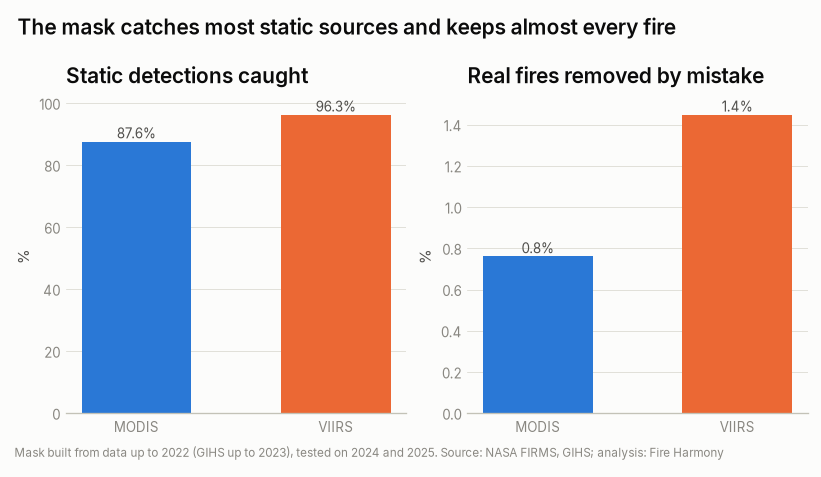

In [5]:
ev = SM.evaluate()
fig, axes = plt.subplots(1, 2, figsize=fh.SIZE['full'])
for ax, col, ttl in [(axes[0], 'recall', 'Static detections caught'), (axes[1], 'fire_loss', 'Real fires removed by mistake')]:
    d = ev[ev.variant.str.startswith('ring 0')]
    ax.bar(d.family, 100 * d[col], color=[fh.SENSOR['MODIS'], fh.SENSOR['VIIRS_SNPP']], width=0.55)
    for i, v in enumerate(100 * d[col]):
        ax.text(i, v, f'{v:.1f}%', ha='center', va='bottom', fontsize=8, color=fh.INK_2)
    fh.clean(ax); ax.set_ylabel('%'); fh.title(ax, ttl)
fig.suptitle('The mask catches most static sources and keeps almost every fire', x=0.01, ha='left', fontsize=12.5, fontweight='semibold')
fh.source(fig, 'Mask built from data up to 2022 (GIHS up to 2023), tested on 2024 and 2025. Source: NASA FIRMS, GIHS; analysis: Fire Harmony')
fig.get_layout_engine().set(rect=(0, 0.04, 1, 0.93)); fh.save(fig, FIG / 'fig04_static_mask_test')
ev.round(4)

## 5. Strange values

Fire radiative power (FRP) tells how strongly a fire burns, in megawatts. A handful of raw values are impossible. We keep those detections but treat their FRP as missing.

In [6]:
con.execute(f'''SELECT sensor, quality, count(*) AS n, min(frp) AS lowest, max(frp) AS highest
  FROM read_parquet({RAW}) WHERE NOT frp BETWEEN 0 AND 20000 GROUP BY ALL ORDER BY n DESC''').df()

,sensor,quality,n,lowest,highest
0,VIIRS_NOAA21,nrt,61,-9.513192e+14,4456712.0
1,MODIS,sp,9,-5.920000e+01,-0.9
2,VIIRS_SNPP,nrt,6,-2.570000e+00,-0.1
3,VIIRS_NOAA20,nrt,5,-1.590000e+00,-0.5


> **Key findings**
>
> - In science quality data, 95% of MODIS and 93% of VIIRS hotspots are vegetation fires. The rest are mostly industry and other static sources.
> - The main confidence rule removes about 5% of MODIS and 12% of VIIRS vegetation hotspots.
> - Tested on 2024 and 2025, years it never saw, our mask catches 96% of VIIRS static detections and wrongly removes only 1.5% of real fires. For MODIS it catches 88% and removes 0.8%.
> - Widening the mask by one ring of neighbours would catch 3 points more MODIS static detections but only 0.3 points more for VIIRS, and it would remove more real fires. Near real time data is mostly VIIRS, so we keep the narrow mask.
> - The open water part removes new offshore sources, such as a platform off north west Australia that appeared in 2026.
> - Only 81 of 640.6 million rows have impossible FRP values (three of them are corrupt NOAA-21 values). We keep those detections and ignore only their FRP.